# Phase 06 — KUB Dataset Characterization (CLEAN-v3)

**Phase ID:** `phase_06_kub_characterization`
**Part:** 1A-R1 — Distribution Interpretation + Stratification + Reviewer-Visualization Repair
**Model:** Gemini 3.8 Flash Medium
**Project Root:** `D:\Softfors\jup` · **Kernel:** `jup-venv`

**Active development manifest:** `phase4_v3`
**Historical manifest:** `phase4_v2`

This notebook characterizes the **clean-v3** KUB development population (TRAIN + VAL).
TEST medical content is never accessed.

> **Part 1A-R1 scope.** This is a targeted repair of Part 1A. The computed geometry is
> accepted and unchanged. The repair fixes: (a) an unsupported "descriptively similar"
> TRAIN/VAL claim, (b) missing stratified geometry summaries, (c) table-registry
> consistency, and (d) gallery presentation. **No population, manifest, or split
> membership was changed.**

## 2. Scientific Question

What are the empirical population, patient, anatomical, acquisition, and
image/object-geometry properties of the **clean-v3** KUB development split —
and how stable are they between TRAIN and VAL?

This is a **descriptive characterization**. It does not define a tiny-object
threshold (Phase 07 does), does not train a model, and does not perform
hypothesis testing.

## 3. CLEAN-v3 Governance

| Rule | Value |
|---|---|
| Medical content used | `manifests/phase4_v3/train.csv`, `manifests/phase4_v3/val.csv` (KUB only) |
| TEST usage | manifest **metadata only** (counts / IDs) |
| TEST content reads | **0** |
| TEST visualizations | **0** |
| TEST metrics | **0** |
| Tiny threshold | **NOT defined here** |
| Training / inference | **NONE** |
| Mask foreground rule | **`mask > 0`** (binary) |

Historical Phase-06 statistics belong to `HISTORICAL_v2` and are shown only for
explicitly-labelled comparison. Primary analysis is recomputed from v3.

In [1]:
import importlib, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import Image as IPImage, display

PROJECT_ROOT = Path(r'D:\Softfors\jup')
CODE_DIR = PROJECT_ROOT / 'notebooks' / 'phasewise' / 'phase_06_kub_characterization' / 'code'
TABLES = PROJECT_ROOT / 'reports' / 'tables'
FIGDIR = PROJECT_ROOT / 'reports' / 'figures' / 'phase06_kub_characterization'
sys.path.insert(0, str(CODE_DIR))
import phase06_kub_characterization as p6

print('python    :', sys.version.split()[0])
print('pandas    :', pd.__version__)
print('numpy     :', np.__version__)
print('module    :', p6.__file__)
print()
print('ACTIVE MANIFEST   :', p6.ACTIVE_MANIFEST_VERSION)
print('HISTORICAL MANIFEST:', p6.HISTORICAL_MANIFEST_VERSION)

python    : 3.11.9
pandas    : 3.0.5
numpy     : 2.4.6
module    : D:\Softfors\jup\notebooks\phasewise\phase_06_kub_characterization\code\phase06_kub_characterization.py

ACTIVE MANIFEST   : phase4_v3
HISTORICAL MANIFEST: phase4_v2


## 4. Population and Provenance

Verify the canonical `phase4_v3` manifest hashes and confirm the KUB counts
match the expected clean-v3 population.

In [2]:
hashes = p6.manifest_hashes()
expected = p6.EXPECTED_V3
rows = []
for k, exp in expected.items():
    act = hashes.get(k)
    rows.append({'manifest': f'phase4_v3/{k}.csv', 'expected_sha256': exp,
                 'actual_sha256': act, 'match': act == exp})
prov = pd.DataFrame(rows)
display(prov)
MANIFEST_OK = bool(prov['match'].all())
print('MANIFEST HASHES OK:', MANIFEST_OK)

,manifest,expected_sha256,actual_sha256,match
0,phase4_v3/all_paired.csv,eb3062fa0e84f9952f994df79ed4d767417a912e18dce8...,eb3062fa0e84f9952f994df79ed4d767417a912e18dce8...,True
1,phase4_v3/train.csv,28702fc3a5ff8b950db372f03232d335e3a30b1fc2f21d...,28702fc3a5ff8b950db372f03232d335e3a30b1fc2f21d...,True
2,phase4_v3/val.csv,082c80b2bda63fd73f371f109c34643adf01edaead9216...,082c80b2bda63fd73f371f109c34643adf01edaead9216...,True
3,phase4_v3/test.csv,9361eba61c91c034a9aa4988a4df229bba591a5cbd553c...,9361eba61c91c034a9aa4988a4df229bba591a5cbd553c...,True
4,phase4_v3/quarantined.csv,a4ec1a8c46692f3c2d55d03c73569ce7b44aeeef734abd...,a4ec1a8c46692f3c2d55d03c73569ce7b44aeeef734abd...,True


MANIFEST HASHES OK: True


In [3]:
train = p6.load_manifest('train')
val   = p6.load_manifest('val')
test  = p6.load_manifest('test')          # metadata only — never decoded
quar  = p6.load_manifest('quarantined')

ktr, kva, ktest, kq = (p6.kub_only(train), p6.kub_only(val),
                       p6.kub_only(test), p6.kub_only(quar))

counts = {'TRAIN': len(ktr), 'VAL': len(kva), 'TEST': len(ktest), 'QUARANTINED': len(kq)}
gate = pd.DataFrame([
    {'split': 'TRAIN', 'expected': p6.EXPECTED_KUB_COUNTS['TRAIN'], 'actual': counts['TRAIN'],
     'match': counts['TRAIN'] == p6.EXPECTED_KUB_COUNTS['TRAIN']},
    {'split': 'VAL', 'expected': p6.EXPECTED_KUB_COUNTS['VAL'], 'actual': counts['VAL'],
     'match': counts['VAL'] == p6.EXPECTED_KUB_COUNTS['VAL']},
    {'split': 'TEST', 'expected': p6.EXPECTED_KUB_COUNTS['TEST'], 'actual': counts['TEST'],
     'match': counts['TEST'] == p6.EXPECTED_KUB_COUNTS['TEST']},
    {'split': 'QUARANTINED', 'expected': p6.EXPECTED_KUB_COUNTS['QUARANTINED'],
     'actual': counts['QUARANTINED'], 'match': counts['QUARANTINED'] == p6.EXPECTED_KUB_COUNTS['QUARANTINED']},
])
display(gate)
HARD_GATE_OK = bool(gate[gate.split.isin(['TRAIN','VAL'])]['match'].all())
assert HARD_GATE_OK, 'CHECK_REQUIRED: KUB TRAIN/VAL count gate failed'
print('KUB TRAIN/VAL hard gate:', HARD_GATE_OK)

,split,expected,actual,match
0,TRAIN,1978,1978,True
1,VAL,280,280,True
2,TEST,558,558,True
3,QUARANTINED,4,4,True


KUB TRAIN/VAL hard gate: True


## 5. Data Integrity Audit

Checked before any characterization: unique IDs, path existence, split
disjointness, patient disjointness, quarantine exclusion, pair readability,
dimension compatibility, and binary mask validity. Nothing is repaired silently.

In [4]:
integ = p6.integrity_audit(ktr, kva, kq, ktest, verify_pixels=True)
integ_df = pd.DataFrame([{'gate': k, 'value': v} for k, v in integ.items()
                          if isinstance(v, (bool, int, float, str))])
display(integ_df)
INTEGRITY_OK = integ['all_gates_pass']
print('ALL INTEGRITY GATES PASS:', INTEGRITY_OK)
print('pairs checked:', integ['pairs_checked'])

,gate,value
0,train_count,1978
1,val_count,280
2,train_count_ok,True
3,val_count_ok,True
4,train_ids_unique,True
5,val_ids_unique,True
6,train_val_sample_overlap,0
7,train_val_patient_overlap,0
8,train_patients,318
9,val_patients,111


ALL INTEGRITY GATES PASS: True
pairs checked: 2258


In [5]:
if integ['empty_masks']:
    print('EMPTY MASKS (reported, not removed):', integ['empty_masks'])
    print(integ['empty_mask_ids'])
else:
    print('Empty masks:', integ['empty_masks'])

Empty masks: 0


## 6. Patient Structure

In [6]:
pat_summary = pd.DataFrame([
    p6.population_summary(ktr, 'TRAIN'),
    p6.population_summary(kva, 'VAL'),
])
display(pat_summary)
print('TRAIN unique patients:', ktr.patient_id.nunique())
print('VAL   unique patients:', kva.patient_id.nunique())
print('TRAIN/VAL patient overlap:', integ['train_val_patient_overlap'])

,split,cases,unique_patients,cases_per_patient_mean,cases_per_patient_median,cases_per_patient_q25,cases_per_patient_q75,cases_per_patient_min,cases_per_patient_max,cases_per_patient_p90,cases_per_patient_p95
0,TRAIN,1978,318,6.220126,5.0,4.0,6.0,1,50,10.0,14.0
1,VAL,280,111,2.522523,3.0,2.0,3.0,1,3,3.0,3.0


TRAIN unique patients: 318
VAL   unique patients: 111
TRAIN/VAL patient overlap: 0


## 7. Anatomical Metadata

> **PIXEL TARGET:** stone/lesion **foreground vs background (binary)**.
> KUB **Kidney / Bladder / Ureteric** are **case-level anatomical metadata**,
> NOT pixel-level multiclass targets.

Raw counts alone obscure proportional differences because TRAIN is far larger
than VAL. Exact **percent-of-split** values and percentage-point differences are
reported below (descriptive only — no significance test).

In [7]:
cat_meta = (pd.concat([ktr.assign(split_label='TRAIN'), kva.assign(split_label='VAL')])
            .groupby(['split_label', 'category']).size().unstack(fill_value=0))
display(cat_meta)
print('Categories present:', sorted(set(ktr.category) | set(kva.category)))
print()
cat_pp = p6.percentage_point_differences(
    pd.concat([ktr.assign(split='TRAIN'), kva.assign(split='VAL')], ignore_index=True),
    'category')
display(cat_pp)
MAX_CATEGORY_PP = float(cat_pp['abs_diff_pp'].max())
print(f'MAX CATEGORY DIFFERENCE: {MAX_CATEGORY_PP:.4f} percentage points')

category,Bladder_Stone,Kidney_Stone,Ureteric_Stone
split_label,,,
TRAIN,634,1133,211
VAL,144,112,24


Categories present: ['Bladder_Stone', 'Kidney_Stone', 'Ureteric_Stone']



,level,train_cases,val_cases,train_pct,val_pct,abs_diff_pp,signed_diff_pp
0,Bladder_Stone,634,144,32.052578,51.428571,19.375993,19.375993
1,Kidney_Stone,1133,112,57.280081,40.000000,17.280081,-17.280081
2,Ureteric_Stone,211,24,10.667341,8.571429,2.095912,-2.095912


MAX CATEGORY DIFFERENCE: 19.3760 percentage points


## 8. Acquisition / Crop Metadata

Acquisition type is derived from the on-disk path layout (ROI crop directory vs
full-field `Images` directory). No category is invented; anything unrecognised
would be reported as `UNKNOWN`.

In [8]:
acq = pd.concat([ktr.assign(split_label='TRAIN'), kva.assign(split_label='VAL')])
acq['acquisition_type'] = acq['image_path'].map(p6.derive_acquisition_type)
acq_tab = acq.groupby(['split_label', 'acquisition_type']).size().unstack(fill_value=0)
display(acq_tab)
print('Acquisition types:', sorted(acq.acquisition_type.unique()))
print()
acq_pp = p6.percentage_point_differences(acq, 'acquisition_type')
display(acq_pp)
MAX_ACQ_PP = float(acq_pp['abs_diff_pp'].max())
print(f'MAX ACQUISITION DIFFERENCE: {MAX_ACQ_PP:.4f} percentage points')
print()
print('Acquisition composition is comparatively SIMILAR between TRAIN and VAL')
print('(max ~2.1 pp), whereas anatomical-category composition differs much more')
print(f'strongly (max ~{MAX_CATEGORY_PP:.1f} pp).')

acquisition_type,FULL_FIELD,ROI
split_label,,
TRAIN,770,1208
VAL,103,177


Acquisition types: ['FULL_FIELD', 'ROI']



,level,train_cases,val_cases,train_pct,val_pct,abs_diff_pp,signed_diff_pp
0,FULL_FIELD,770,103,38.92821,36.785714,2.142496,-2.142496
1,ROI,1208,177,61.07179,63.214286,2.142496,2.142496


MAX ACQUISITION DIFFERENCE: 2.1425 percentage points

Acquisition composition is comparatively SIMILAR between TRAIN and VAL
(max ~2.1 pp), whereas anatomical-category composition differs much more
strongly (max ~19.4 pp).


## 8b. Full Geometry Characterization (TRAIN + VAL)

The reusable module extracts, for every active KUB pair: image dimensions, mask
foreground area/fraction, connected-component count, largest-component area and
fraction, bounding-box dimensions/area, equivalent diameter, and normalised
centroid. This may take a few minutes over 2,258 pairs.

In [9]:
geo_tr = p6.characterize_population(ktr, 'TRAIN')
geo_va = p6.characterize_population(kva, 'VAL')
geo = pd.concat([geo_tr, geo_va], ignore_index=True)
print('characterized:', len(geo), 'pairs')
print('columns:', list(geo.columns))
display(geo.head(3))

characterized: 2258 pairs
columns: ['image_width', 'image_height', 'image_pixels', 'aspect_ratio', 'image_mode', 'fg_pixels', 'fg_fraction', 'component_count', 'largest_component_pixels', 'largest_component_fraction', 'nonlargest_component_pixels', 'bbox_width', 'bbox_height', 'bbox_area', 'bbox_area_fraction', 'equivalent_diameter', 'equivalent_diameter_largest', 'centroid_y_norm', 'centroid_x_norm', 'sample_id', 'split', 'patient_id', 'category', 'acquisition_type', 'image_path', 'mask_path', 'native_resolution']


,image_width,image_height,image_pixels,aspect_ratio,image_mode,fg_pixels,fg_fraction,component_count,largest_component_pixels,largest_component_fraction,...,centroid_y_norm,centroid_x_norm,sample_id,split,patient_id,category,acquisition_type,image_path,mask_path,native_resolution
0,3072,3072,9437184,1.0,RGB,4763,0.000505,1,4763,0.000505,...,0.713643,0.520766,ecb2b0b5e962b0642665cd8b2da8f23b,TRAIN,patient-00003,Bladder_Stone,FULL_FIELD,D:\Softfors\omni_seg\data_raw\KUB-Stone\KUB-St...,D:\Softfors\omni_seg\data_raw\KUB-Stone\KUB-St...,3072x3072
1,3072,3072,9437184,1.0,RGB,4148,0.000440,1,4148,0.000440,...,0.855954,0.428588,84d7aa903794899c130127bb8b835ba0,TRAIN,patient-00004,Bladder_Stone,FULL_FIELD,D:\Softfors\omni_seg\data_raw\KUB-Stone\KUB-St...,D:\Softfors\omni_seg\data_raw\KUB-Stone\KUB-St...,3072x3072
2,3072,3072,9437184,1.0,RGB,616,0.000065,1,616,0.000065,...,0.791057,0.478813,63c84da18b33b023ab32c7374f27f74d,TRAIN,patient-00005,Bladder_Stone,FULL_FIELD,D:\Softfors\omni_seg\data_raw\KUB-Stone\KUB-St...,D:\Softfors\omni_seg\data_raw\KUB-Stone\KUB-St...,3072x3072


## 9. Native Image Geometry

In [10]:
series = {'TRAIN': geo_tr, 'VAL': geo_va, 'COMBINED': geo}
img_q = p6.image_geometry_quantile_table(series)
display(img_q)
print('Image modes:', geo.image_mode.value_counts().to_dict())

,metric,group,n,P01,P05,P10,P25,P50,P75,P90,P95,P99,min,max,mean
0,image_width,TRAIN,1978,53.000000,58.000000,64.000000,78.00,141.000000,2304.0,2.304000e+03,3.024000e+03,3.072000e+03,47.000000,3.096000e+03,1.014704e+03
1,image_width,VAL,280,47.790000,53.950000,57.000000,68.00,106.000000,2304.0,3.072000e+03,3.072000e+03,3.072000e+03,41.000000,3.072000e+03,1.004511e+03
2,image_width,COMBINED,2258,52.000000,57.000000,63.000000,76.00,134.500000,2304.0,2.304000e+03,3.072000e+03,3.072000e+03,41.000000,3.096000e+03,1.013440e+03
3,image_height,TRAIN,1978,54.000000,60.000000,65.000000,82.00,154.000000,2880.0,2.880000e+03,3.072000e+03,3.528000e+03,49.000000,3.528000e+03,1.229444e+03
4,image_height,VAL,280,49.790000,54.000000,58.900000,69.75,115.500000,2880.0,3.072000e+03,3.440000e+03,3.528000e+03,45.000000,3.528000e+03,1.188871e+03
5,image_height,COMBINED,2258,53.000000,59.000000,64.000000,80.00,146.000000,2880.0,3.072000e+03,3.281200e+03,3.528000e+03,45.000000,3.528000e+03,1.224413e+03
6,aspect_ratio,TRAIN,1978,0.562913,0.671080,0.737209,0.80,0.857143,1.0,1.112980e+00,1.209954e+00,1.406780e+00,0.444444,1.793103e+00,9.003115e-01
7,aspect_ratio,VAL,280,0.613371,0.695614,0.737209,0.80,0.909989,1.0,1.105760e+00,1.146228e+00,1.229574e+00,0.471814,1.281690e+00,9.118951e-01
8,aspect_ratio,COMBINED,2258,0.569722,0.673896,0.737209,0.80,0.857143,1.0,1.111528e+00,1.200319e+00,1.392683e+00,0.444444,1.793103e+00,9.017479e-01
9,image_pixels,TRAIN,1978,2955.810000,3565.500000,4231.300000,6396.00,21085.000000,6635520.0,6.635520e+06,9.437184e+06,1.066867e+07,2448.000000,1.066867e+07,2.846737e+06


Image modes: {'L': 1385, 'RGB': 873}


### 9b. Two Distinct Acquisition Regimes

Native geometry is **bimodal by acquisition type**: ROI crops are small and
highly variable; FULL_FIELD images are large and comparatively standardised.
Aggregate quantiles therefore span a very wide range and should always be read
alongside this stratification. The **image mode** also differs by regime
(RGB for FULL_FIELD, single-channel `L` for ROI).

In [11]:
regime_df = p6.acquisition_regime_geometry(geo)
p6.write_table(regime_df, 'phase06_kub_v3_acquisition_regime_geometry.csv', TABLES)
display(regime_df)
print('Top native resolutions overall:')
display(p6.resolution_summary(geo).head(10))

,acquisition_type,cases,distinct_native_resolutions,width_min,width_median,width_max,height_median,image_modes,top_resolution,top_resolution_count
0,FULL_FIELD,873,35,1476,2304.0,3096,2880.0,RGB,2304x2880,638
1,ROI,1385,1199,41,83.0,495,89.0,L,53x55,4


Top native resolutions overall:


split,native_resolution,TRAIN,VAL,total
0,2304x2880,590,48,638
1,3072x3072,82,31,113
2,3024x3528,47,4,51
3,2536x3440,26,11,37
4,69x67,4,0,4
5,71x77,4,0,4
6,63x65,3,1,4
7,64x64,3,1,4
8,53x55,4,0,4
9,69x68,2,1,3


## 10. Mask / Object Geometry

The pixel target is **binary** (`mask > 0`). KUB masks use a **heterogeneous
nonzero label vocabulary** that is category-correlated; every nonzero value maps
to foreground. This is documented below — it is a data-semantics property, not
corruption.

In [12]:
vocab = p6.mask_label_vocabulary(geo[['split', 'category', 'mask_path']])
display(vocab)

import json
print('Mask label vocabulary with counts (from integrity audit):')
print(json.dumps(integ['mask_label_vocabulary'], indent=2))
print('All nonzero labels observed:', integ['mask_label_union'])
print('Foreground semantics:', integ['mask_foreground_semantics'])
print()
print('NOTE: label 255 and labels 1/2/3 are all FOREGROUND under `mask > 0`.')
print('      The binary target is unaffected by which nonzero label is used.')
print('      Labels 1/2/3/255 must NOT be interpreted as multiclass segmentation')
print('      labels, and downstream code must NOT assume `mask == 1`.')

,label_signature,category,cases
0,0|1,Kidney_Stone,465
1,0|1|2,Bladder_Stone,3
2,0|2,Bladder_Stone,304
3,0|255,Bladder_Stone,471
4,0|255,Kidney_Stone,780
5,0|255,Ureteric_Stone,134
6,0|3,Ureteric_Stone,101


Mask label vocabulary with counts (from integrity audit):
{
  "0|1": 465,
  "0|1|2": 3,
  "0|2": 304,
  "0|3": 101,
  "0|255": 1385
}
All nonzero labels observed: [0, 1, 2, 3, 255]
Foreground semantics: binary: foreground = (mask > 0)

NOTE: label 255 and labels 1/2/3 are all FOREGROUND under `mask > 0`.
      The binary target is unaffected by which nonzero label is used.
      Labels 1/2/3/255 must NOT be interpreted as multiclass segmentation
      labels, and downstream code must NOT assume `mask == 1`.


> **Downstream governance statement.**
> All CLEAN-v3 KUB segmentation loaders and target-generation code must binarize
> the native mask as **`(mask > 0)`**. Phase 08 infrastructure must unit-test this
> invariant before clean model training.
> *(Phase-08 code is NOT modified in this repair.)*

In [13]:
mask_q = p6.mask_geometry_quantile_table(series)
display(mask_q)

,metric,group,n,P01,P05,P10,P25,P50,P75,P90,P95,P99,min,max,mean
0,fg_pixels,TRAIN,1978,423.310000,593.700000,744.400000,1227.000000,2637.500000,6829.000000,17970.300000,30301.900000,91953.710000,259.000000,3.791340e+05,8265.773509
1,fg_pixels,VAL,280,261.490000,441.900000,529.000000,833.500000,1574.500000,4078.750000,8588.500000,19176.300000,75441.020000,222.000000,1.354610e+05,5275.228571
2,fg_pixels,COMBINED,2258,392.280000,553.850000,705.000000,1164.250000,2480.500000,6305.500000,17331.800000,30062.150000,89140.340000,222.000000,3.791340e+05,7894.935341
3,fg_fraction,TRAIN,1978,0.000070,0.000123,0.000195,0.000691,0.209909,0.326324,0.414634,0.459254,0.543468,0.000027,6.588715e-01,0.190249
4,fg_fraction,VAL,280,0.000052,0.000090,0.000130,0.000535,0.188260,0.288454,0.374094,0.423460,0.525630,0.000024,5.823462e-01,0.172453
5,fg_fraction,COMBINED,2258,0.000065,0.000116,0.000186,0.000659,0.208051,0.321339,0.410305,0.457682,0.542583,0.000024,6.588715e-01,0.188042
6,component_count,TRAIN,1978,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,2.000000,5.000000,1.000000,1.200000e+01,1.204752
7,component_count,VAL,280,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,1.000000,2.000000e+00,1.175000
8,component_count,COMBINED,2258,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,2.000000,5.000000,1.000000,1.200000e+01,1.201063
9,largest_component_pixels,TRAIN,1978,419.160000,587.400000,721.400000,1188.250000,2511.500000,6246.500000,17210.300000,28145.200000,85309.840000,259.000000,1.313130e+05,7148.734075


## 11. Connected-Component Structure

KUB masks are **not assumed** to contain exactly one connected object. The
multi-component rate differs materially between TRAIN and VAL.

In [14]:
comp_struct = p6.component_structure_summary(geo)
display(comp_struct)
print('MAX components in a single case:', int(geo.component_count.max()))
print()
mc_tr_n = int((geo_tr.component_count >= 2).sum())
mc_va_n = int((geo_va.component_count >= 2).sum())
MC_TRAIN_PCT = 100.0 * mc_tr_n / len(geo_tr)
MC_VAL_PCT = 100.0 * mc_va_n / len(geo_va)
print(f'TRAIN multi-component: {mc_tr_n}/{len(geo_tr)} = {MC_TRAIN_PCT:.4f}%')
print(f'VAL   multi-component: {mc_va_n}/{len(geo_va)} = {MC_VAL_PCT:.4f}%')
print(f'Difference (VAL - TRAIN): {MC_VAL_PCT - MC_TRAIN_PCT:+.4f} percentage points')
print()
print('This is a DESCRIPTIVE difference requiring stratified reading.')

,split,cases,empty_masks,empty_pct,single_component,single_pct,multi_component,multi_pct,total_components,max_components_in_case
0,TRAIN,1978,0,0.0,1766,89.282103,212,10.717897,2383,12
1,VAL,280,0,0.0,231,82.500000,49,17.500000,329,2


MAX components in a single case: 12

TRAIN multi-component: 212/1978 = 10.7179%
VAL   multi-component: 49/280 = 17.5000%
Difference (VAL - TRAIN): +6.7821 percentage points

This is a DESCRIPTIVE difference requiring stratified reading.


## 12. Continuous Object-Size Distributions

Phase 07 formally defines tiny-object criteria. **No threshold is chosen or
frozen here.** These distributions are empirical evidence for that later
definition.

In [15]:
geo_q = p6.geometry_quantile_table(series)
display(geo_q)

,metric,group,n,P01,P05,P10,P25,P50,P75,P90,P95,P99,min,max,mean
0,fg_pixels,TRAIN,1978,423.310000,593.700000,744.400000,1227.000000,2637.500000,6829.000000,17970.300000,30301.900000,91953.710000,259.000000,379134.000000,8265.773509
1,fg_pixels,VAL,280,261.490000,441.900000,529.000000,833.500000,1574.500000,4078.750000,8588.500000,19176.300000,75441.020000,222.000000,135461.000000,5275.228571
2,fg_pixels,COMBINED,2258,392.280000,553.850000,705.000000,1164.250000,2480.500000,6305.500000,17331.800000,30062.150000,89140.340000,222.000000,379134.000000,7894.935341
3,fg_fraction,TRAIN,1978,0.000070,0.000123,0.000195,0.000691,0.209909,0.326324,0.414634,0.459254,0.543468,0.000027,0.658871,0.190249
4,fg_fraction,VAL,280,0.000052,0.000090,0.000130,0.000535,0.188260,0.288454,0.374094,0.423460,0.525630,0.000024,0.582346,0.172453
5,fg_fraction,COMBINED,2258,0.000065,0.000116,0.000186,0.000659,0.208051,0.321339,0.410305,0.457682,0.542583,0.000024,0.658871,0.188042
6,largest_component_pixels,TRAIN,1978,419.160000,587.400000,721.400000,1188.250000,2511.500000,6246.500000,17210.300000,28145.200000,85309.840000,259.000000,131313.000000,7148.734075
7,largest_component_pixels,VAL,280,256.750000,410.150000,516.500000,801.750000,1386.500000,4022.500000,7413.500000,17185.050000,74249.220000,222.000000,87133.000000,4722.264286
8,largest_component_pixels,COMBINED,2258,378.140000,540.000000,691.100000,1115.500000,2317.000000,5666.500000,16630.100000,27611.650000,81011.800000,222.000000,131313.000000,6847.843224
9,largest_component_fraction,TRAIN,1978,0.000067,0.000109,0.000174,0.000618,0.209909,0.326324,0.414634,0.459254,0.543468,0.000027,0.658871,0.190101


## 13. TRAIN-vs-VAL Descriptive Differences

TRAIN and VAL are **patient-disjoint** but are **not compositionally identical**.
The differences below are **descriptive** — they are **not** significance tests,
and they do **not** invalidate the split.

In [16]:
cat_df = p6.category_summary(geo)
acq_df = p6.acquisition_summary(geo)
display(cat_df)
display(acq_df)
print('Category max |Δ pct-pt| TRAIN vs VAL   :', round(MAX_CATEGORY_PP, 4))
print('Acquisition max |Δ pct-pt| TRAIN vs VAL:', round(MAX_ACQ_PP, 4))
print('Multi-component Δ (VAL - TRAIN)        :', round(MC_VAL_PCT - MC_TRAIN_PCT, 4), 'pp')
print()
print('The clean-v3 TRAIN and VAL populations are patient-disjoint but are not')
print('compositionally identical. Anatomical-category prevalence shows a')
print('material descriptive shift, especially for Bladder/Kidney composition.')
print()
print('This is NOT a statistical significance claim and does NOT invalidate the split.')

,category,TRAIN_cases,TRAIN_pct,VAL_cases,VAL_pct
0,Bladder_Stone,634,32.052578,144,51.428571
1,Kidney_Stone,1133,57.280081,112,40.000000
2,Ureteric_Stone,211,10.667341,24,8.571429


,acquisition_type,TRAIN_cases,TRAIN_pct,VAL_cases,VAL_pct
0,FULL_FIELD,770,38.92821,103,36.785714
1,ROI,1208,61.07179,177,63.214286


Category max |Δ pct-pt| TRAIN vs VAL   : 19.376
Acquisition max |Δ pct-pt| TRAIN vs VAL: 2.1425
Multi-component Δ (VAL - TRAIN)        : 6.7821 pp

The clean-v3 TRAIN and VAL populations are patient-disjoint but are not
compositionally identical. Anatomical-category prevalence shows a
material descriptive shift, especially for Bladder/Kidney composition.

This is NOT a statistical significance claim and does NOT invalidate the split.


### 13b. Patient Case-Burden and Geometry Differences

In [17]:
burden_rows = []
for sp, sub in geo.groupby('split'):
    per = sub.groupby('patient_id').size()
    burden_rows.append({
        'split': sp,
        'patients': int(sub.patient_id.nunique()),
        'cases_per_patient_median': float(per.median()),
        'cases_per_patient_max': int(per.max()),
        'cases_per_patient_mean': float(per.mean()),
    })
display(pd.DataFrame(burden_rows))

geom_rows = []
for col in ['fg_fraction', 'largest_component_pixels', 'bbox_area_fraction']:
    geom_rows.append({
        'metric': col,
        'train_median': float(np.median(geo_tr[col])),
        'val_median': float(np.median(geo_va[col])),
        'abs_diff': float(abs(np.median(geo_tr[col]) - np.median(geo_va[col]))),
    })
display(pd.DataFrame(geom_rows))
print('These are descriptive differences requiring stratified reading (see 13c).')

,split,patients,cases_per_patient_median,cases_per_patient_max,cases_per_patient_mean
0,TRAIN,318,5.0,50,6.220126
1,VAL,111,3.0,3,2.522523


,metric,train_median,val_median,abs_diff
0,fg_fraction,0.209909,0.188260,0.021648
1,largest_component_pixels,2511.500000,1386.500000,1125.000000
2,bbox_area_fraction,0.316573,0.269914,0.046659


These are descriptive differences requiring stratified reading (see 13c).


### 13c. Stratified Geometry (Mixture-Aware)

Aggregate geometry mixes two very different acquisition regimes, so combined
quantiles are **mixture statistics**. The table below stratifies by
`split × acquisition_type` and `split × anatomical category`.

Descriptive only — **no significance tests**.

In [18]:
strat = p6.stratified_geometry_summary(geo)
p6.write_table(strat, 'phase06_kub_v3_stratified_geometry_summary.csv', TABLES)
pd.set_option('display.max_columns', 40)
display(strat[['dimension_a', 'dimension_b', 'n',
               'foreground_fraction_p25', 'foreground_fraction_median', 'foreground_fraction_p75',
               'largest_component_pixels_median', 'bbox_area_fraction_median',
               'equivalent_diameter_median', 'component_count_median']])
STRAT_SHA = p6.sha256_file(TABLES / 'phase06_kub_v3_stratified_geometry_summary.csv')
print('stratified geometry SHA:', STRAT_SHA)

,dimension_a,dimension_b,n,foreground_fraction_p25,foreground_fraction_median,foreground_fraction_p75,largest_component_pixels_median,bbox_area_fraction_median,equivalent_diameter_median,component_count_median
0,split x acquisition_type,TRAIN | FULL_FIELD,770,0.000192,0.000443,0.001243,2728.0,0.000831,61.983871,1.0
1,split x acquisition_type,TRAIN | ROI,1208,0.234107,0.301572,0.378099,2330.0,0.457120,54.466940,1.0
2,split x acquisition_type,VAL | FULL_FIELD,103,0.000122,0.000242,0.000631,1442.0,0.000845,50.751981,1.0
3,split x acquisition_type,VAL | ROI,177,0.197314,0.258766,0.336357,1352.0,0.374815,41.489997,1.0
4,split x category,TRAIN | Bladder_Stone,634,0.000211,0.171509,0.234441,998.5,0.253901,36.746018,1.0
5,split x category,TRAIN | Kidney_Stone,1133,0.001616,0.277344,0.371073,4499.0,0.420988,77.784538,1.0
6,split x category,TRAIN | Ureteric_Stone,211,0.000418,0.188796,0.303491,2550.0,0.300868,57.403344,1.0
7,split x category,VAL | Bladder_Stone,144,0.000173,0.151820,0.217676,886.0,0.233228,33.964025,1.0
8,split x category,VAL | Kidney_Stone,112,0.001038,0.284062,0.369563,4262.5,0.420549,74.762775,1.0
9,split x category,VAL | Ureteric_Stone,24,0.160962,0.250600,0.326033,1587.0,0.382250,48.039699,1.0


stratified geometry SHA: bffb72858cdb042f1c4f5b0b9b0987c49a84434df0ad99cc9427ea14b00957fa


### 13d. Percentage-Normalized Category Comparison

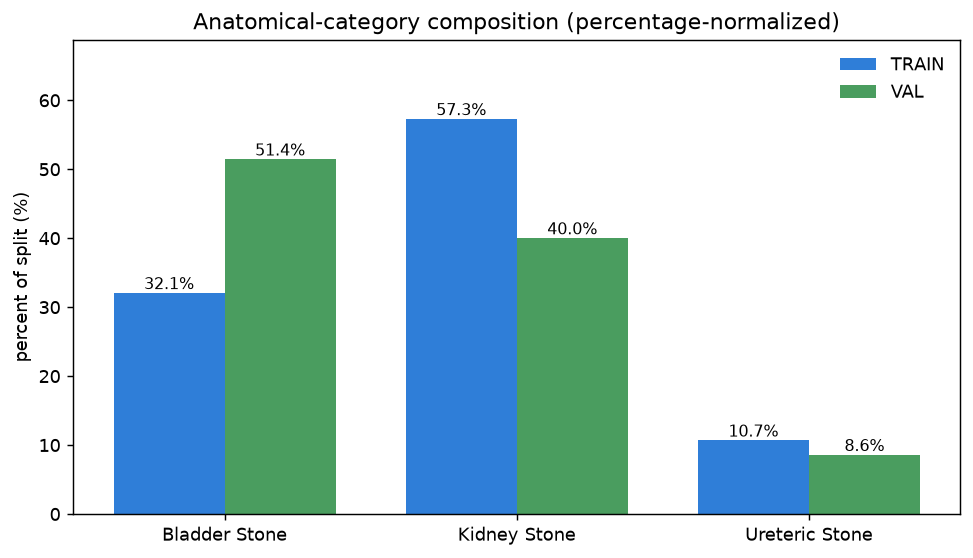

Raw counts obscure proportional differences because TRAIN is much larger;
this percentage-normalized view makes the composition shift visible.
No significance stars and no p-values are used.


In [19]:
fig = p6.plot_category_normalized(geo)
gpath = p6.save_fig(fig, p6.PROJECT_ROOT / 'reports' / 'figures' /
                    'phase06_kub_characterization' / 'phase06_kub_v3_category_normalized.png')
display(IPImage(filename=str(gpath)))
print('Raw counts obscure proportional differences because TRAIN is much larger;')
print('this percentage-normalized view makes the composition shift visible.')
print('No significance stars and no p-values are used.')

### 13e. Stratified Geometry Figures

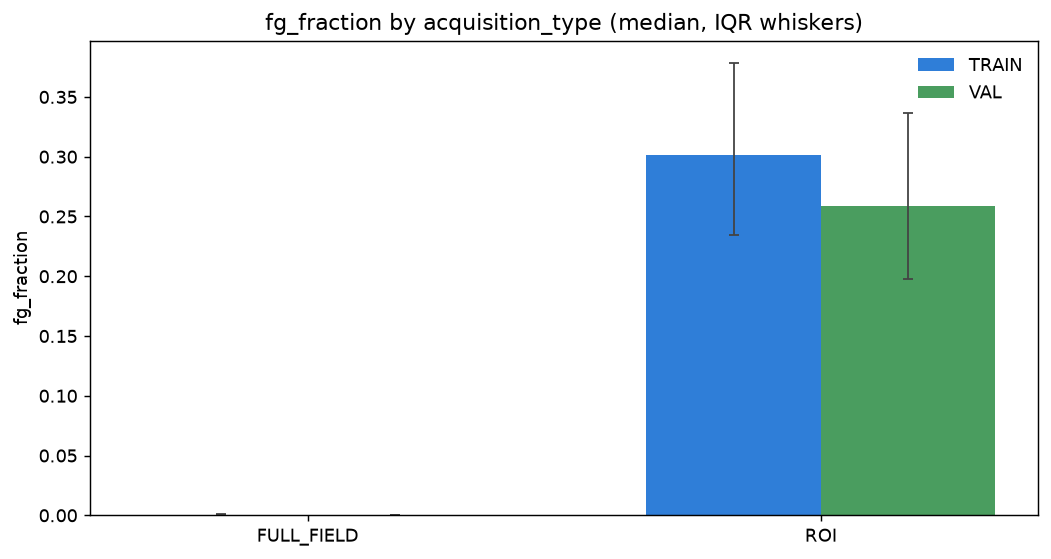

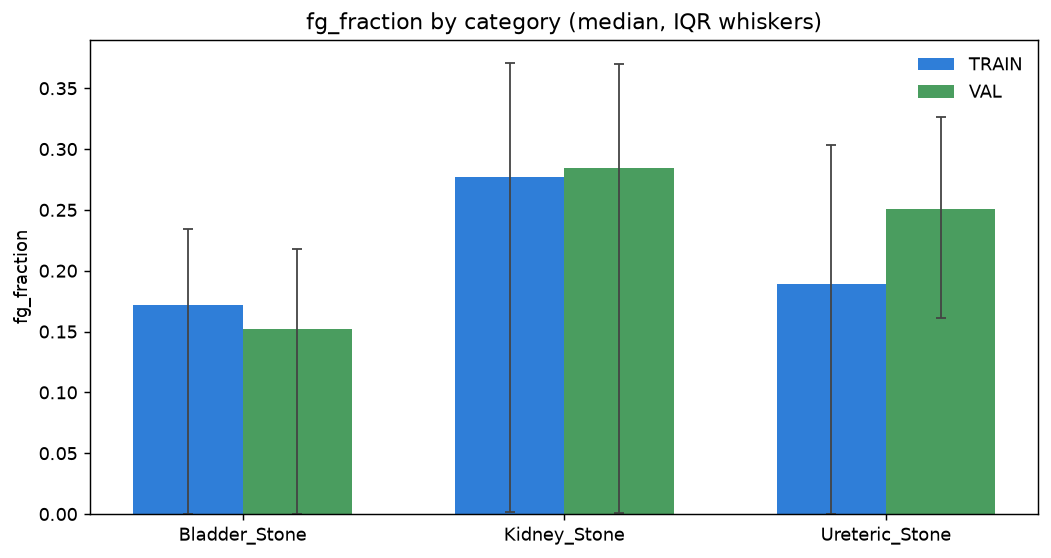

In [20]:
for fname, dim, metric in [
    ('phase06_kub_v3_stratified_acquisition_fg.png', 'acquisition_type', 'fg_fraction'),
    ('phase06_kub_v3_stratified_category_fg.png', 'category', 'fg_fraction'),
]:
    fig = p6.plot_stratified_geometry(geo, dim, metric)
    gp = p6.save_fig(fig, p6.PROJECT_ROOT / 'reports' / 'figures' /
                     'phase06_kub_characterization' / fname)
    display(IPImage(filename=str(gp)))

## 14. Quarantined KUB Metadata

In [21]:
qmeta = p6.quarantined_metadata(kq)
display(qmeta)
print('Quarantined KUB cases:', len(qmeta))
print('Reasons:', qmeta['quarantine_reason'].value_counts().to_dict() if 'quarantine_reason' in qmeta else {})
print('Excluded from all active TRAIN/VAL statistics: YES')

,sample_id,patient_id,split_v2,quarantine_reason,duplicate_asset_group_id,duplicate_risk_group_id,category,dataset
0,ef36ad8332b2f33882dc668a5b6846e5,patient-00173,TRAIN,QUARANTINED_TEST_LINKED_PHASH_HIGH_RISK,NaN,RISK_GROUP_TEST_PHASH_002,Bladder_Stone,KUB
1,5c2a14deb7948564d7b538aa41b07e12,patient-00268,VAL,QUARANTINED_TEST_LINKED_PHASH_HIGH_RISK,NaN,RISK_GROUP_TEST_PHASH_007,Bladder_Stone,KUB
2,a62708e2834fab0c56d4f575f49f7c61,patient-00320,VAL,QUARANTINED_EXACT_DUPLICATE,GROUP_KUB_001,NaN,Kidney_Stone,KUB
3,ff96d383c86c30902bd89e6c39190923,patient-00406,VAL,CONSERVATIVE_HIGH_RISK_GROUPING,NaN,RISK_GROUP_d2_016,Kidney_Stone,KUB


Quarantined KUB cases: 4
Reasons: {'QUARANTINED_TEST_LINKED_PHASH_HIGH_RISK': 2, 'QUARANTINED_EXACT_DUPLICATE': 1, 'CONSERVATIVE_HIGH_RISK_GROUPING': 1}
Excluded from all active TRAIN/VAL statistics: YES


## 15. Deterministic Sample-Selection Protocol

Selection is **deterministic, documented, prediction-independent, and not
cherry-picked**. It stratifies by (split, category, acquisition), orders by
stable `sample_id`, and adds continuous foreground-fraction quantile-bin
coverage. Size diversity uses **continuous quantiles only** — no tiny label.

In [22]:
sel = p6.deterministic_sample_selection(geo, n_total=16)
sel_cols = ['selection_rank', 'sample_id', 'split', 'patient_id', 'category',
            'acquisition_type', 'native_resolution', 'fg_pixels', 'fg_fraction',
            'component_count', 'largest_component_pixels', 'bbox_width', 'bbox_height',
            'bbox_area_fraction', 'equivalent_diameter', 'image_path', 'mask_path']
sel_out = sel[[c for c in sel_cols if c in sel.columns]]
SELECTION_SHA = p6.sha256_of_strings(sel_out['sample_id'].tolist())
display(sel_out.drop(columns=['image_path', 'mask_path']))
print('SAMPLE SELECTION SHA:', SELECTION_SHA)
print('gallery cases:', len(sel_out))
print('split coverage :', sel_out.split.value_counts().to_dict())
print('category cover :', sel_out.category.value_counts().to_dict())
print('acquisition    :', sel_out.acquisition_type.value_counts().to_dict())

,selection_rank,sample_id,split,patient_id,category,acquisition_type,native_resolution,fg_pixels,fg_fraction,component_count,largest_component_pixels,bbox_width,bbox_height,bbox_area_fraction,equivalent_diameter
0,1,298e2e83fd890132332ddb9bde2f6cbb,TRAIN,patient-00375,Kidney_Stone,ROI,105x123,2552,0.197600,1,2552,77,94,0.560434,57.002696
1,2,39b4f559575e4a209d47f6aa82753a4b,TRAIN,patient-00362,Kidney_Stone,FULL_FIELD,2304x2880,1545,0.000233,1,1545,58,50,0.000437,44.352622
2,3,66a54286e40051386dd860703a40149f,VAL,patient-00427,Kidney_Stone,ROI,97x138,4044,0.302107,1,4044,69,108,0.556701,71.756398
3,4,69ad6c24d1fe02ba1eae73189ee875ea,VAL,patient-00094,Bladder_Stone,ROI,63x66,787,0.189274,1,787,34,38,0.310726,31.655008
4,5,776e8a18d67468bff36086ca4f3c9d85,TRAIN,patient-00662,Ureteric_Stone,ROI,77x72,1686,0.304113,1,1686,49,45,0.397727,46.332298
5,6,78880b4420a45b93f20800102a825846,TRAIN,patient-00003,Bladder_Stone,ROI,103x121,4887,0.392121,1,4887,75,95,0.571692,78.881694
6,7,7f8ff6a340fd02dcad6a058a2a36c501,TRAIN,patient-00579,Ureteric_Stone,FULL_FIELD,2304x2880,1417,0.000214,1,1417,37,68,0.000379,42.475645
7,8,80677b81c42fce3c61f5942cd57602a3,TRAIN,patient-00255,Bladder_Stone,FULL_FIELD,2304x2880,673,0.000101,1,673,28,32,0.000135,29.272687
8,9,84f1b2ab8dd16a5da43192da34940ea2,VAL,patient-00296,Kidney_Stone,ROI,73x111,2421,0.298778,1,2421,44,82,0.445267,55.520383
9,10,854f7ca399b41c027de9526f232b39b0,TRAIN,patient-00560,Kidney_Stone,FULL_FIELD,2636x3456,372320,0.040869,9,105483,1870,1029,0.211221,688.514740


SAMPLE SELECTION SHA: 7324b7cc91f4c39b76bfd80e78d14154d0e91ec165f727d4c43dfb82fac1d485
gallery cases: 16
split coverage : {'TRAIN': 9, 'VAL': 7}
category cover : {'Kidney_Stone': 7, 'Bladder_Stone': 5, 'Ureteric_Stone': 4}
acquisition    : {'ROI': 9, 'FULL_FIELD': 7}


## 16. Detailed Medical Gallery (deterministic, 16 cases, TRAIN/VAL only)

The gallery uses the **same deterministic 16 sample IDs** as before — no
reselection and no cherry-picking by visual quality.

Each case is shown as **three panels**:
1. original image
2. **binary** ground-truth mask (`mask > 0`) — not the raw heterogeneous labels
3. GT overlay on the original (+ bounding box)

Because 16 × 3 panels would be unreadable as a single postage stamp, the gallery
is paginated into **4 pages × 4 cases**.

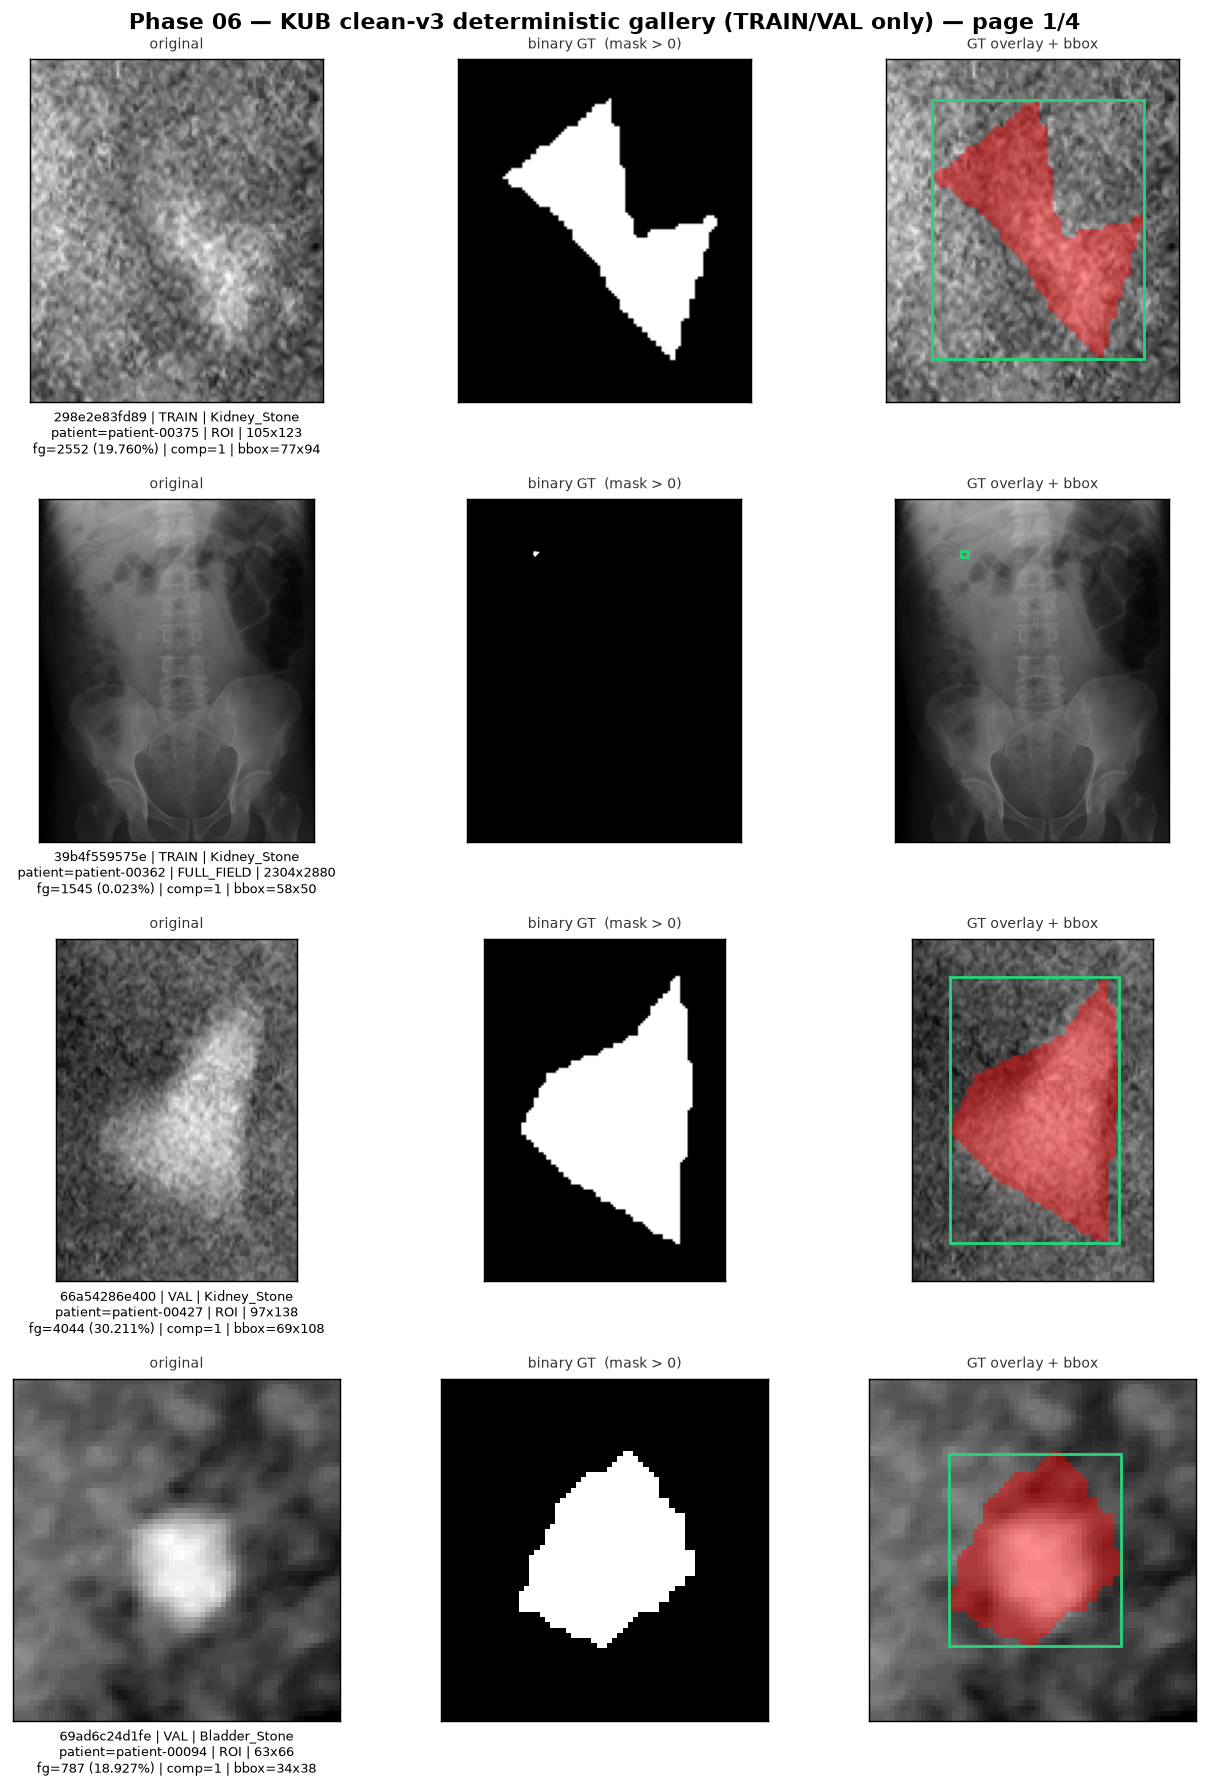

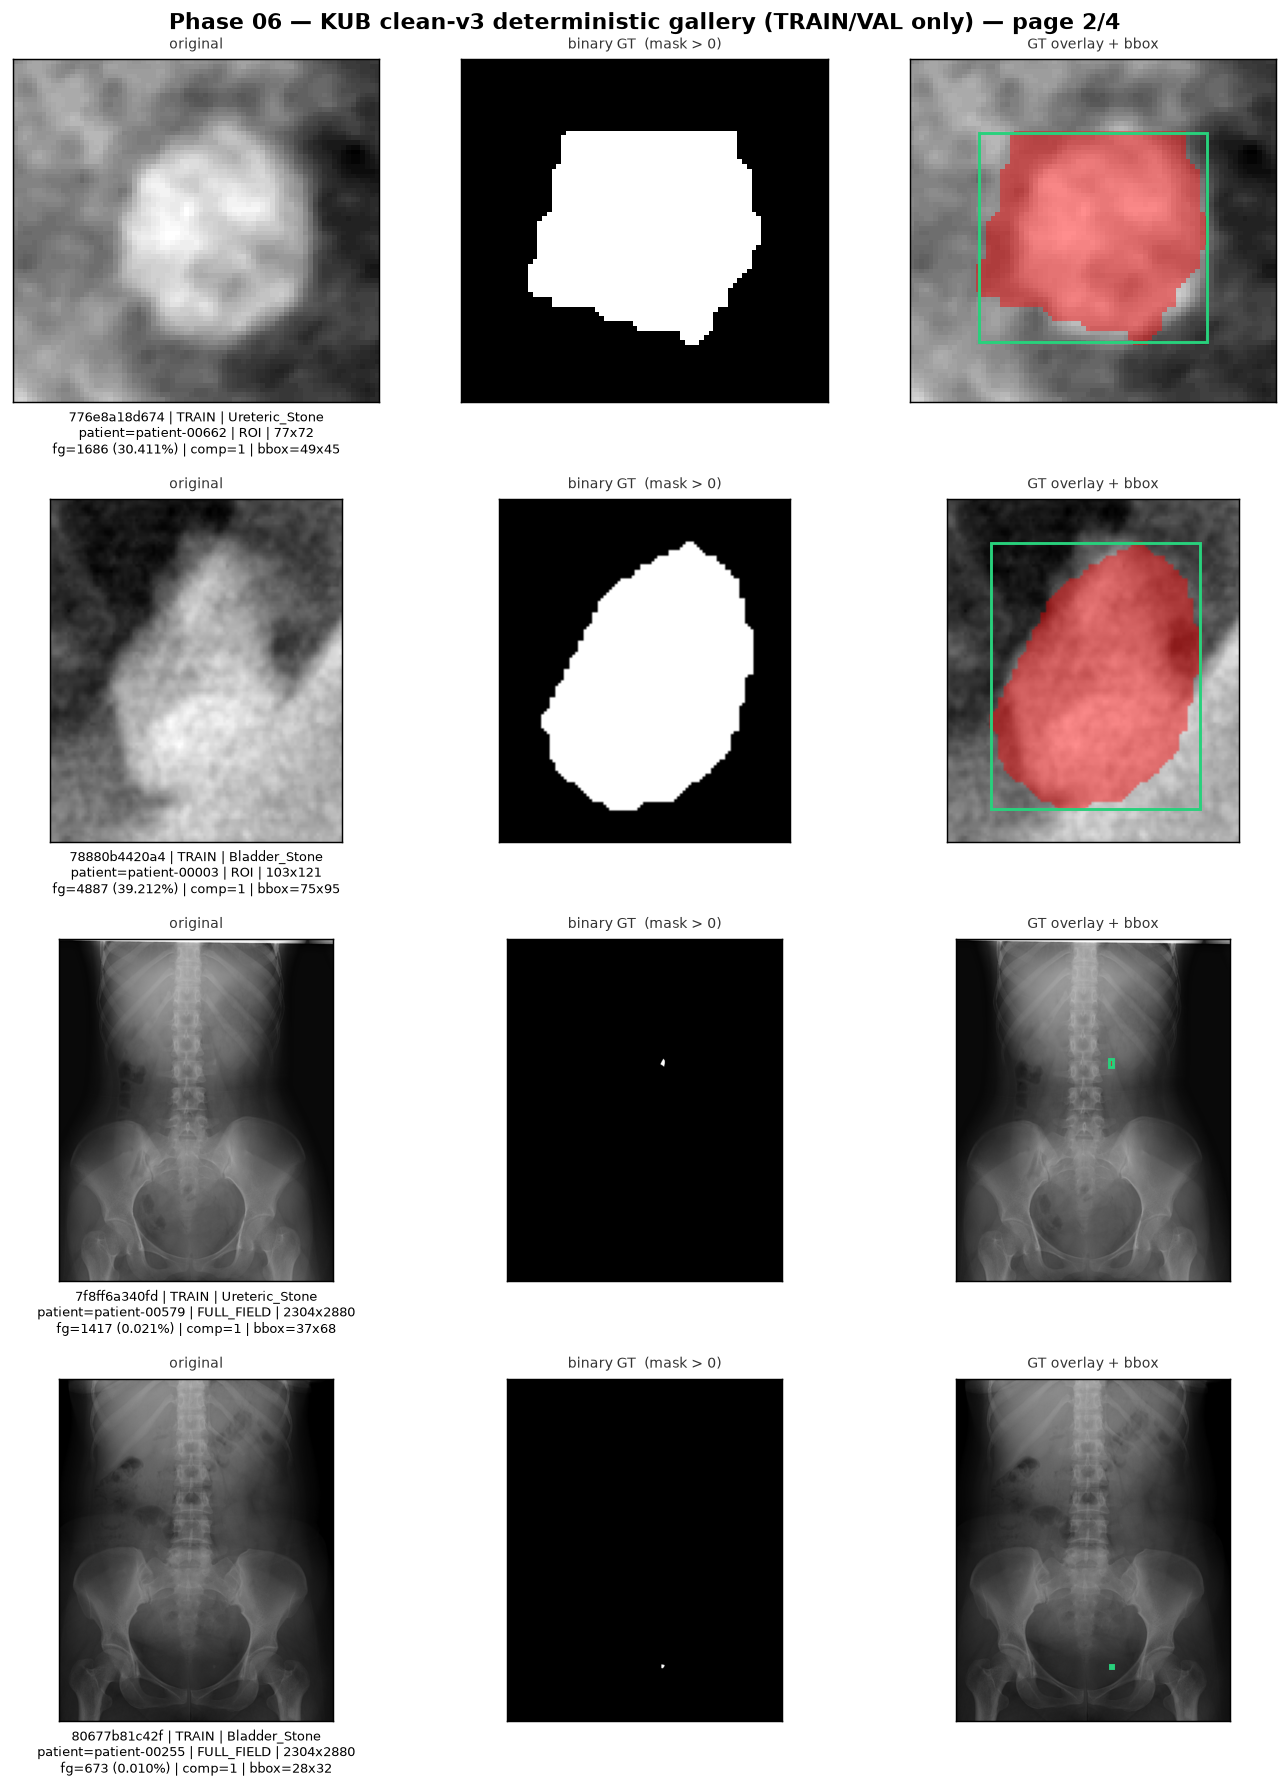

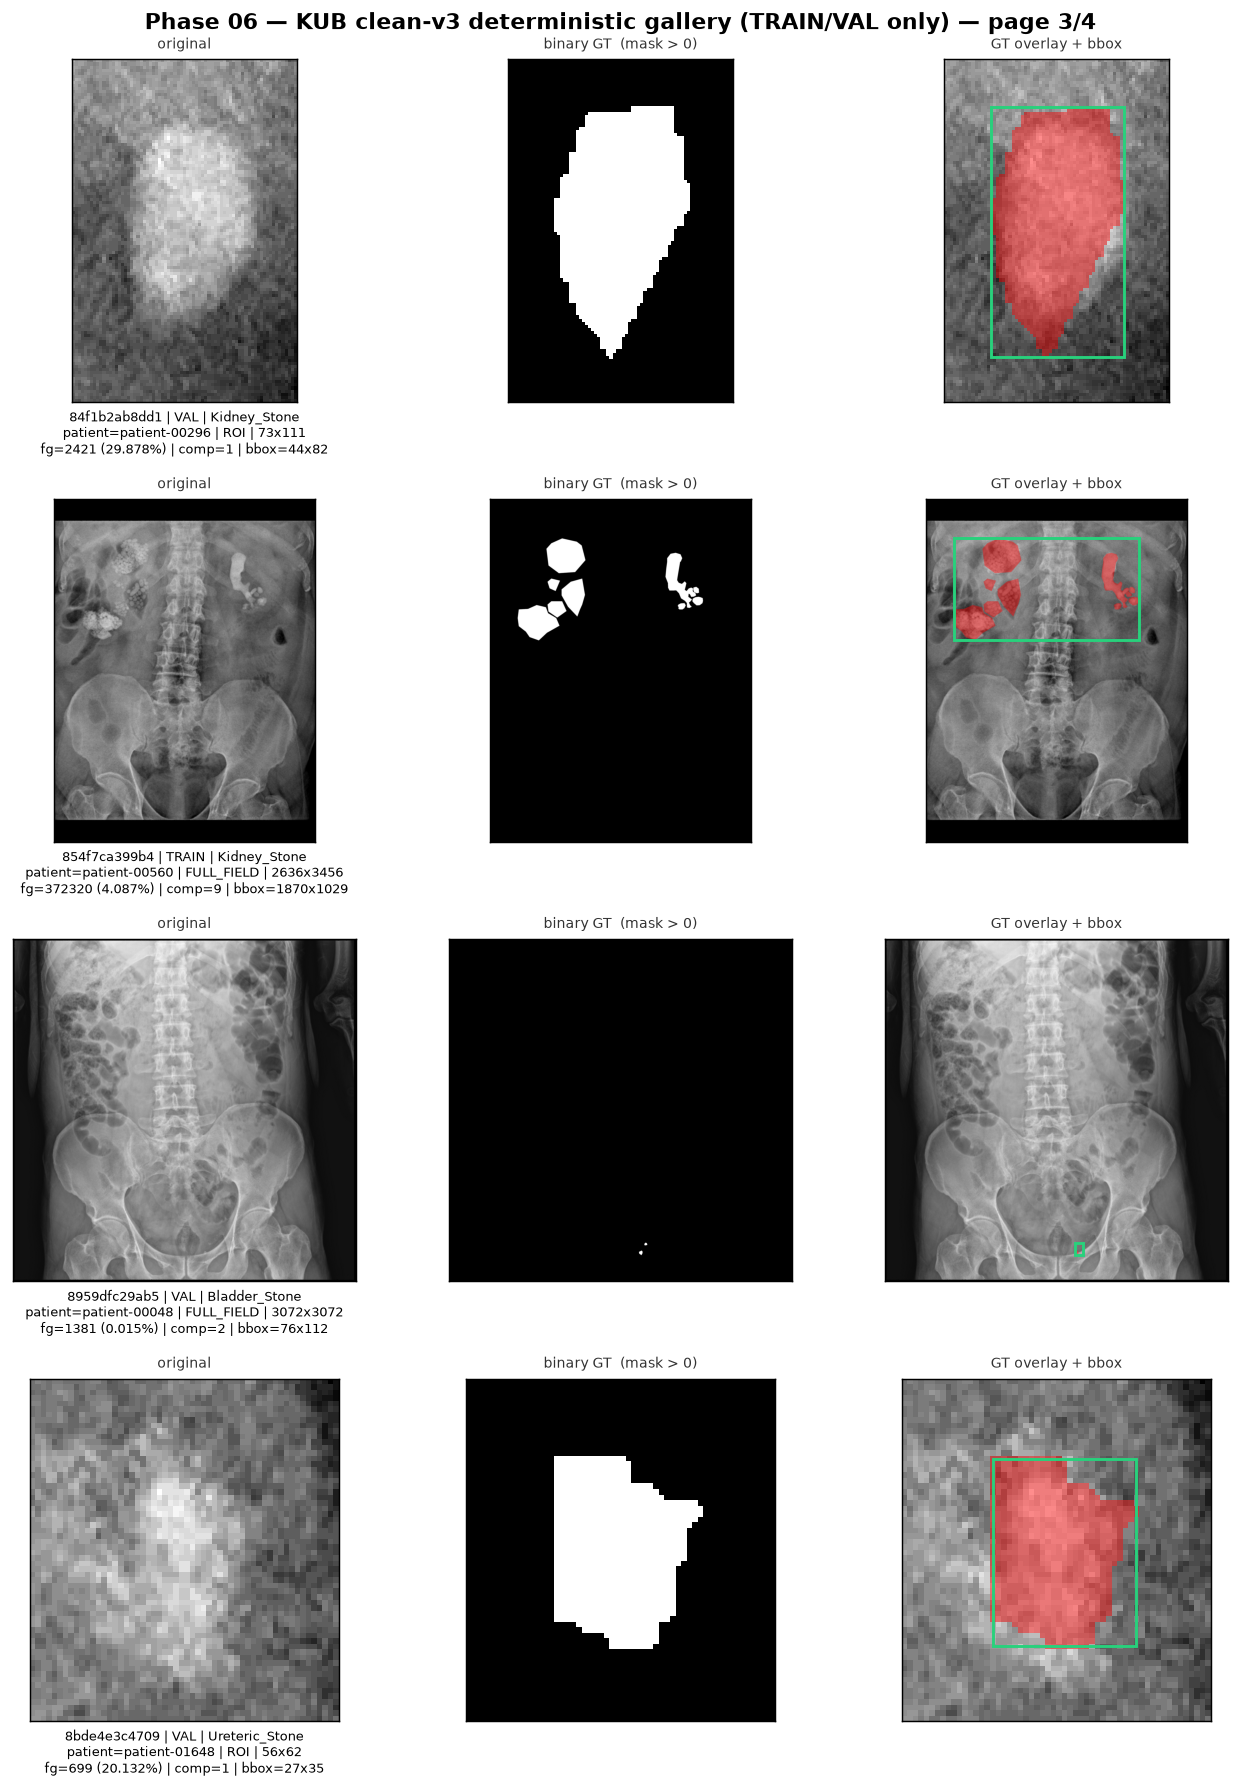

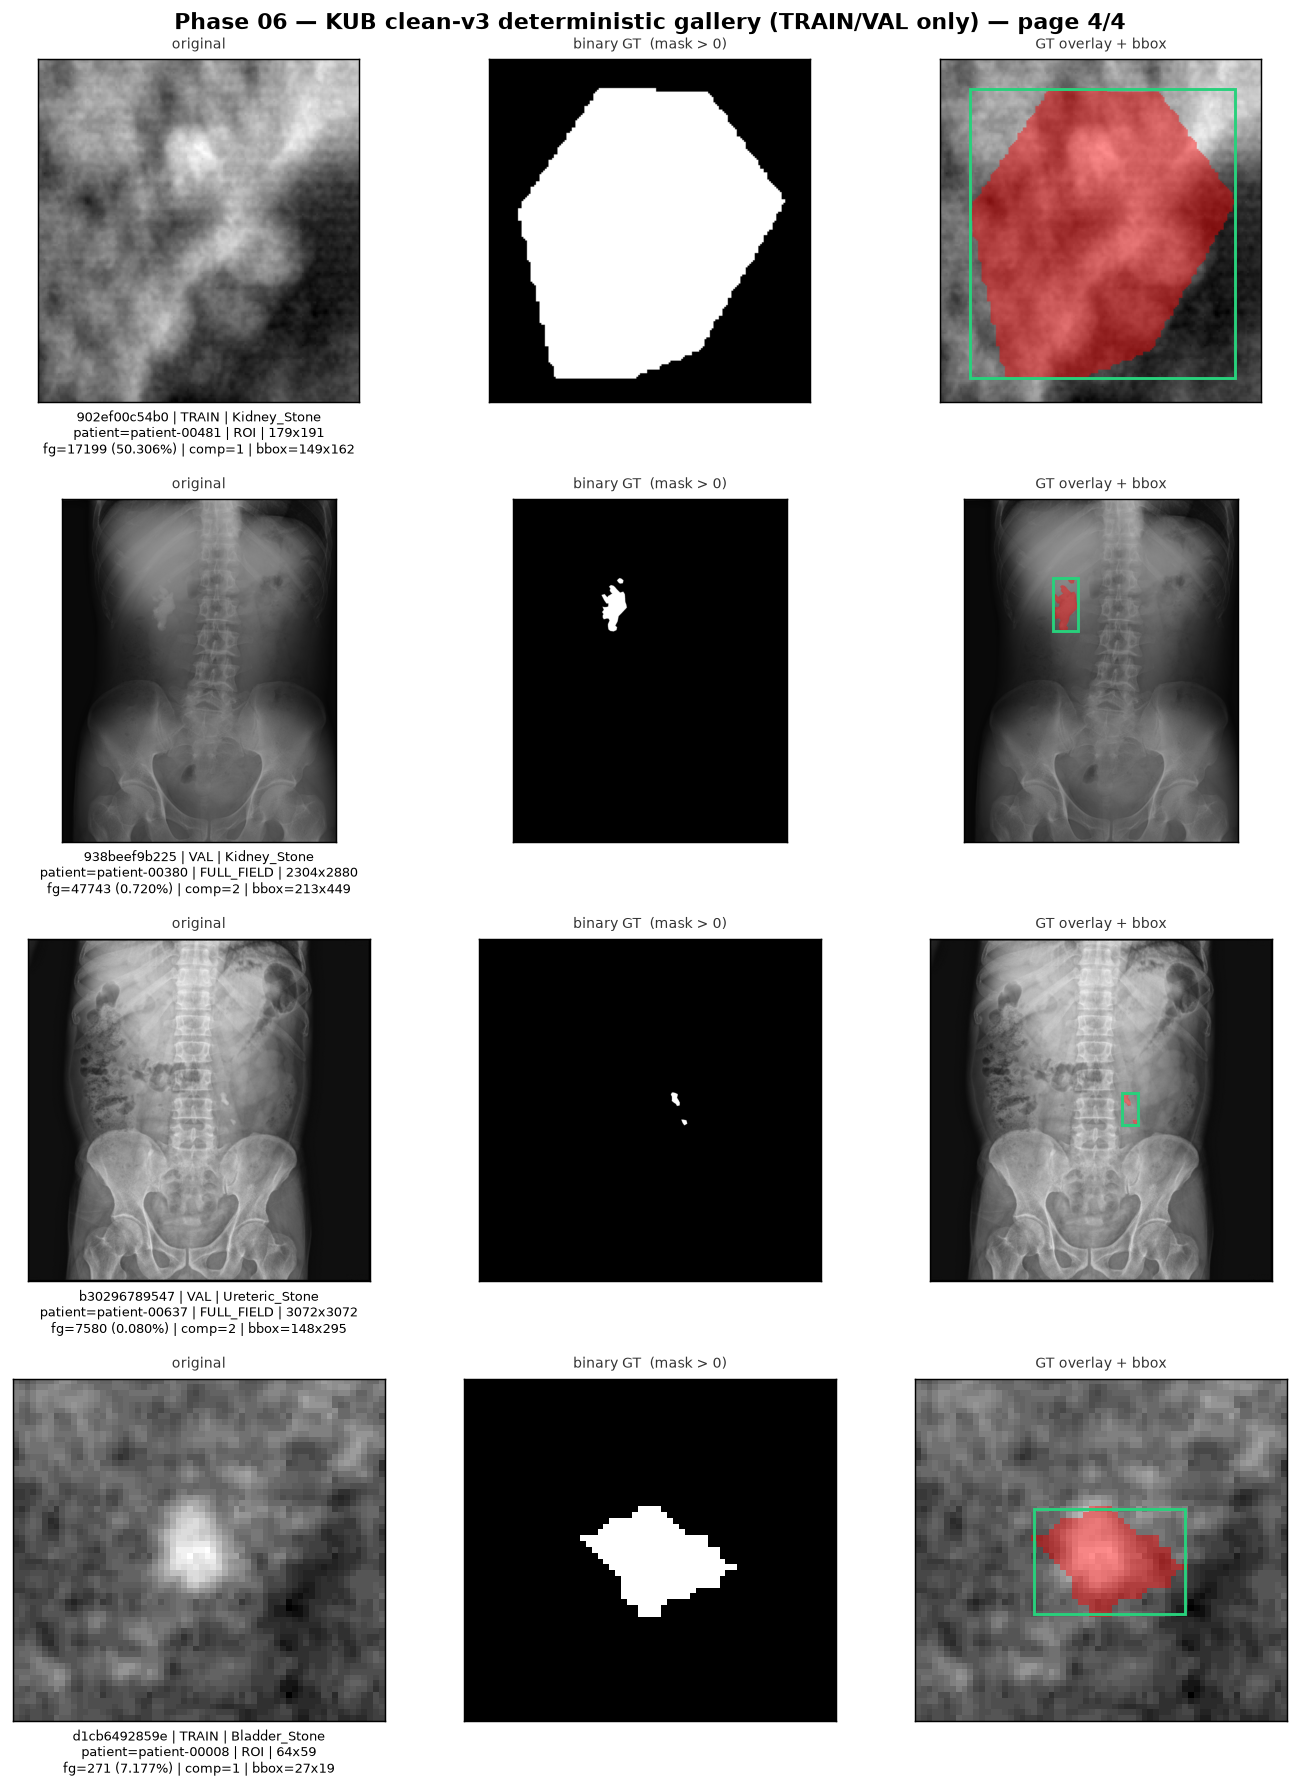

gallery pages: 4
cases rendered: 16 (TEST content reads: 0)
each case shows: original + binary GT (mask>0) + GT overlay


In [23]:
gal_figs = p6.plot_gallery_pages(
    sel_out, cases_per_page=4,
    title='Phase 06 — KUB clean-v3 deterministic gallery (TRAIN/VAL only)')
GALLERY_PAGES = []
for i, f in enumerate(gal_figs, 1):
    gp = p6.save_fig(f, p6.PROJECT_ROOT / 'reports' / 'figures' /
                     'phase06_kub_characterization' /
                     f'phase06_kub_v3_medical_gallery_page{i:02d}.png')
    GALLERY_PAGES.append(gp)
    display(IPImage(filename=str(gp)))
print('gallery pages:', len(GALLERY_PAGES))
print('cases rendered:', len(sel_out), '(TEST content reads: 0)')
print('each case shows: original + binary GT (mask>0) + GT overlay')

## 17. Required Characterization Figures

### Figure 1 — KUB v3 TRAIN/VAL population composition

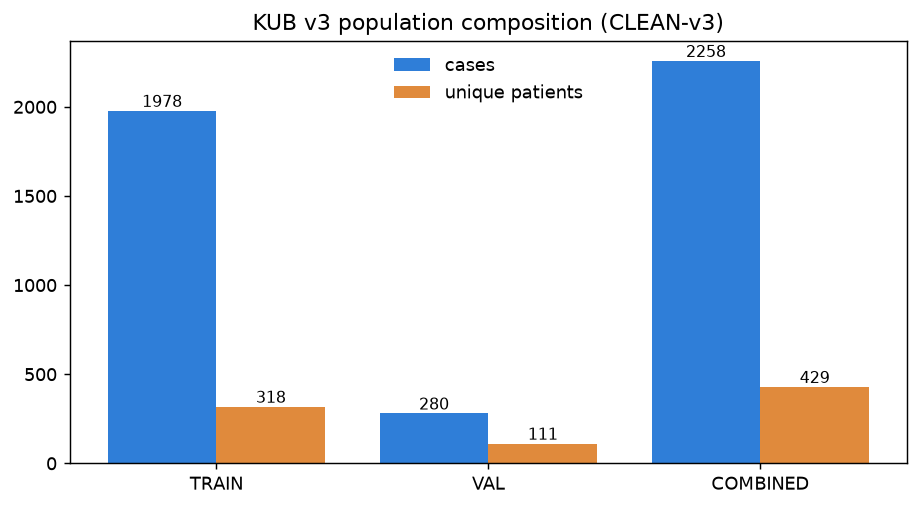

In [24]:
display(IPImage(filename=str(p6.PROJECT_ROOT / 'reports' / 'figures' /
    'phase06_kub_characterization' / 'phase06_kub_v3_population_composition.png')))

### Figure 2 — Anatomical-category distribution

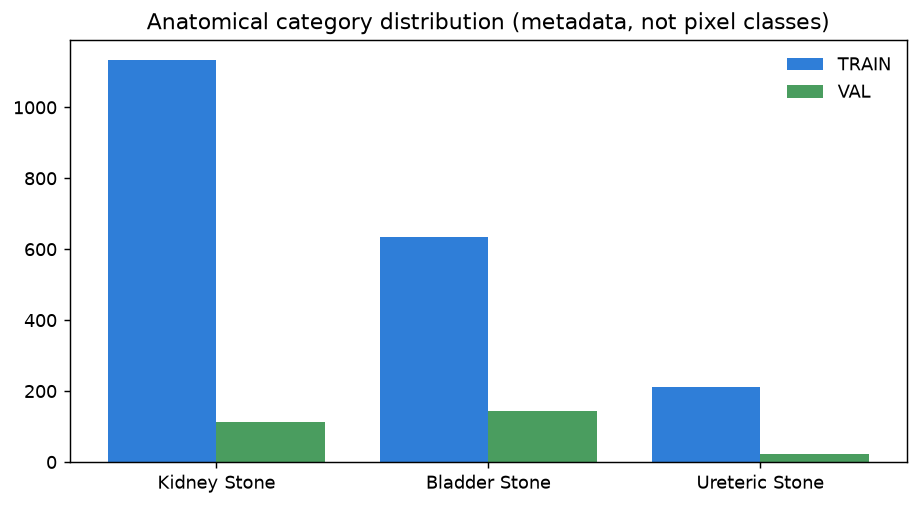

In [25]:
display(IPImage(filename=str(p6.PROJECT_ROOT / 'reports' / 'figures' /
    'phase06_kub_characterization' / 'phase06_kub_v3_category_distribution.png')))

### Figure 3 — Acquisition / crop-type distribution

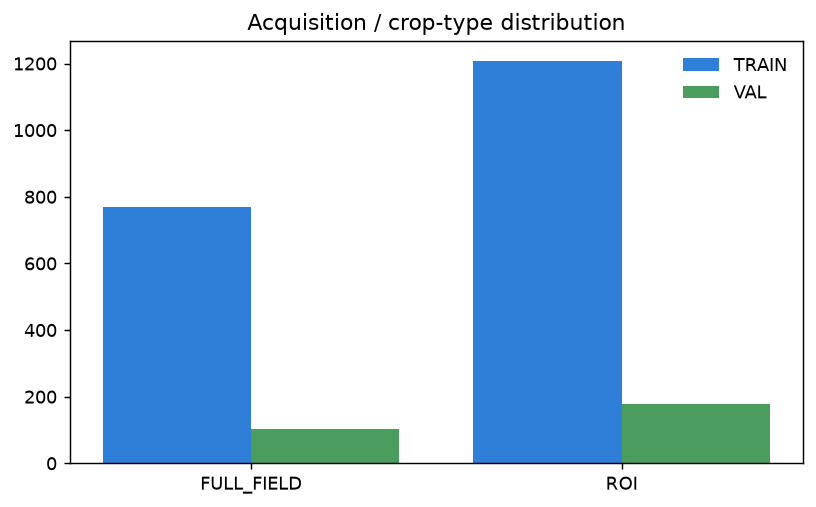

In [26]:
display(IPImage(filename=str(p6.PROJECT_ROOT / 'reports' / 'figures' /
    'phase06_kub_characterization' / 'phase06_kub_v3_acquisition_distribution.png')))

### Figure 4 — Native-resolution distribution

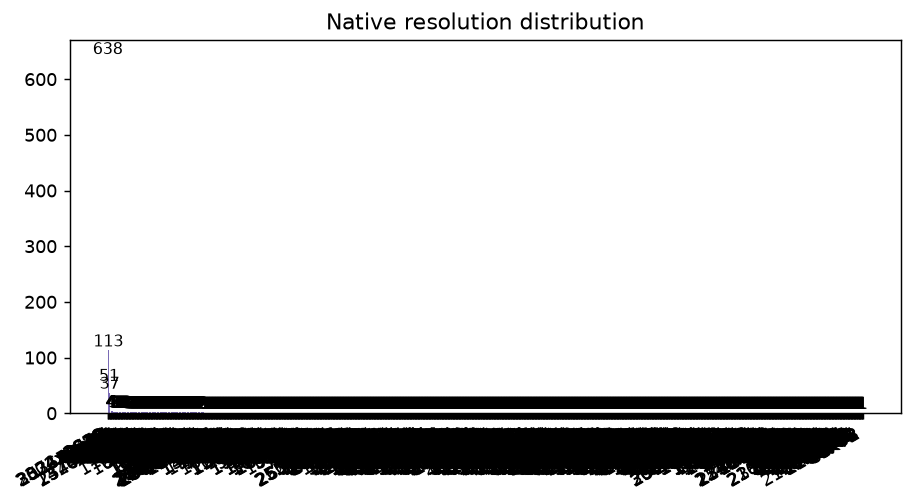

In [27]:
display(IPImage(filename=str(p6.PROJECT_ROOT / 'reports' / 'figures' /
    'phase06_kub_characterization' / 'phase06_kub_v3_native_resolution.png')))

### Figure 5 — Foreground-fraction distribution

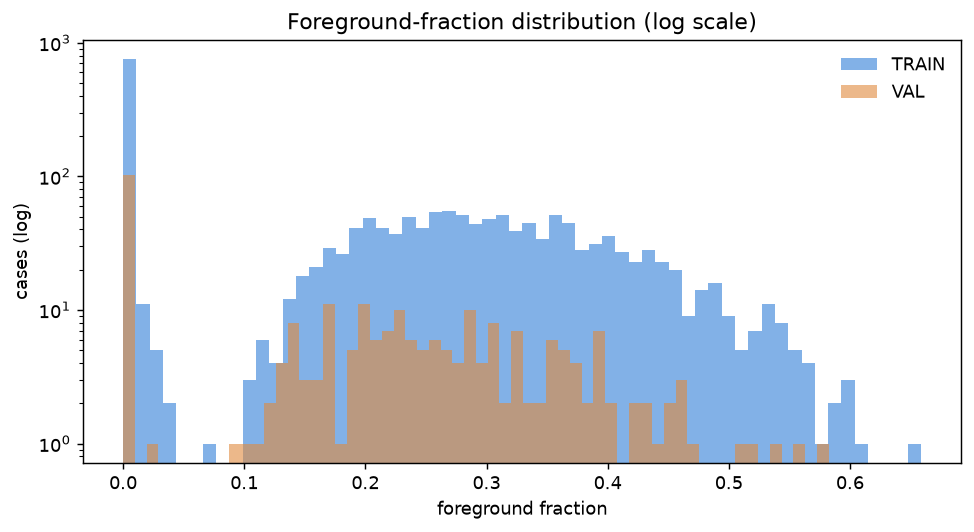

In [28]:
display(IPImage(filename=str(p6.PROJECT_ROOT / 'reports' / 'figures' /
    'phase06_kub_characterization' / 'phase06_kub_v3_fg_fraction_distribution.png')))

### Figure 6 — Largest-component / equivalent-size distribution

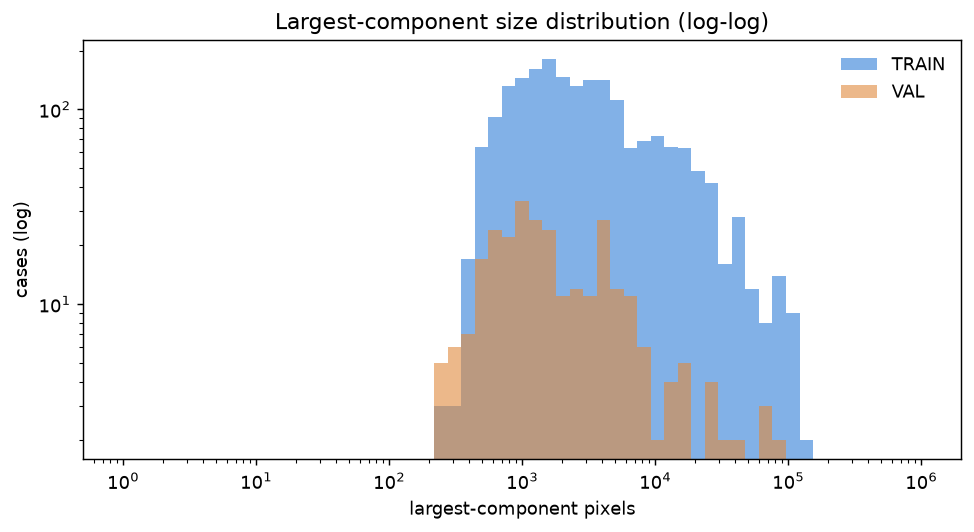

In [29]:
display(IPImage(filename=str(p6.PROJECT_ROOT / 'reports' / 'figures' /
    'phase06_kub_characterization' / 'phase06_kub_v3_largest_component_distribution.png')))

### Figure 7 — Bounding-box size distribution

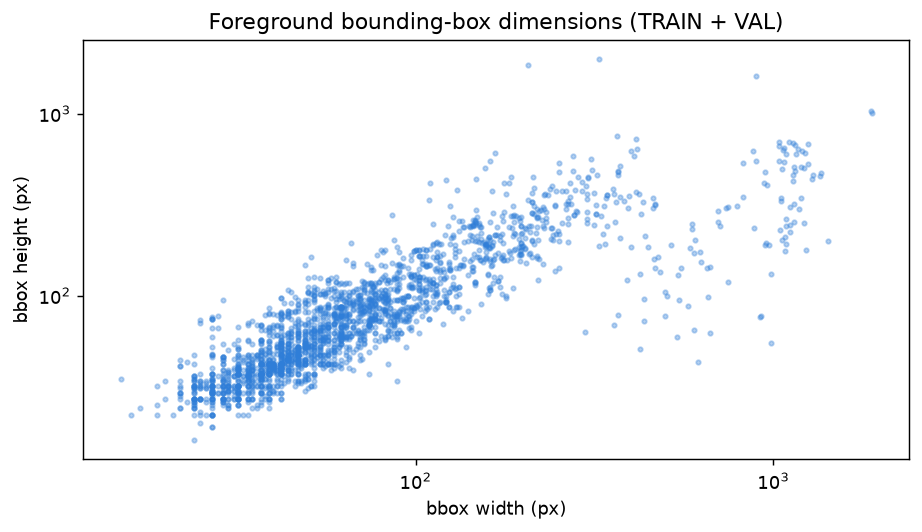

In [30]:
display(IPImage(filename=str(p6.PROJECT_ROOT / 'reports' / 'figures' /
    'phase06_kub_characterization' / 'phase06_kub_v3_bbox_size_distribution.png')))

### Figure 8 — Component-count distribution

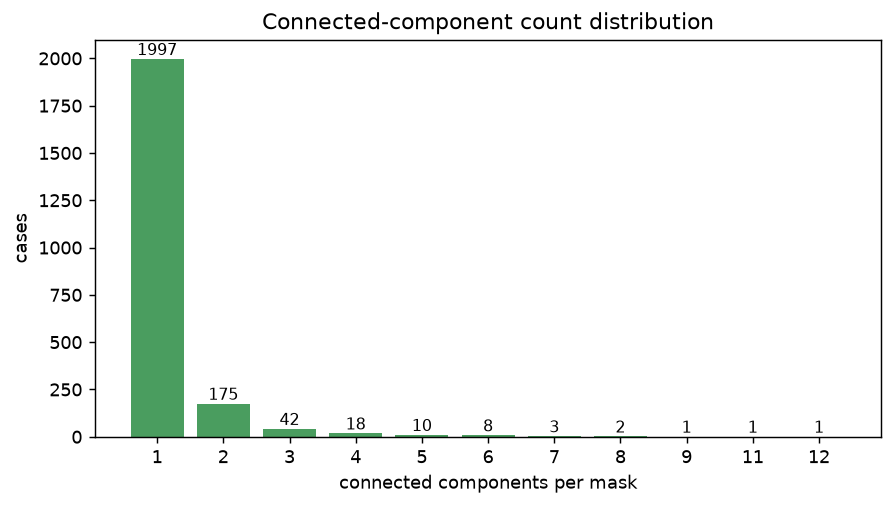

In [31]:
display(IPImage(filename=str(p6.PROJECT_ROOT / 'reports' / 'figures' /
    'phase06_kub_characterization' / 'phase06_kub_v3_component_count_distribution.png')))

### Figure 9 — TRAIN-vs-VAL geometry comparison

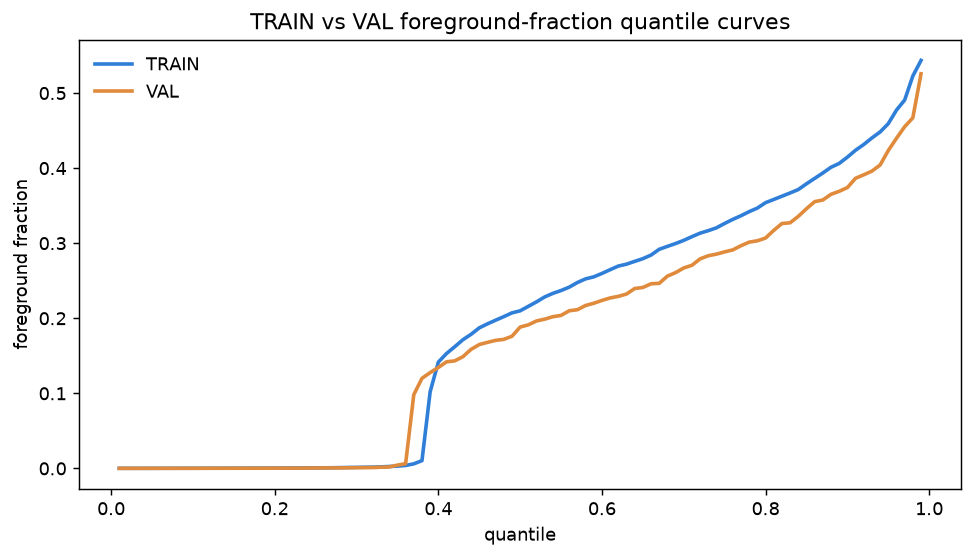

In [32]:
display(IPImage(filename=str(p6.PROJECT_ROOT / 'reports' / 'figures' /
    'phase06_kub_characterization' / 'phase06_kub_v3_train_val_geometry_comparison.png')))

## 18. Interpretation

- The clean-v3 population and **patient-disjointness are verified**
  (**1978 TRAIN / 280 VAL** cases over **318 / 111** unique patients,
  **zero** TRAIN-VAL patient overlap).
- Native mask labels are **heterogeneous** but cleanly map to **one binary
  foreground target** via `mask > 0`. Any code that assumes `label == 1` is wrong.
- `FULL_FIELD` and `ROI` geometry are **strongly different regimes**
  (median width 2304 vs 83; RGB vs single-channel `L`), so combined quantiles
  are **mixture statistics**.
- **TRAIN and VAL are NOT compositionally identical**, especially in
  anatomical-category proportions (max difference ≈ 19.38 pp: Bladder 32.05% →
  51.43%; Kidney 57.28% → 40.00%). Acquisition composition is comparatively
  similar (max ≈ 2.14 pp). Multi-component rates differ (10.72% → 17.50%).
- Some **aggregate geometry differences may reflect mixture/composition effects**
  and must be interpreted with the stratified summaries (section 13c).
- These facts **do not justify changing the frozen v3 split**.
- They **do affect how Phase 07 defines and evaluates object-size strata**.

## 19. Limitations

- Analysis uses **KUB TRAIN/VAL development data only**.
- **TEST medical content remains locked** (0 reads, 0 visualisations, 0 metrics).
- Geometry depends on the available **binary** masks.
- **Kidney / Bladder / Ureteric are metadata**, not multiclass pixel labels.
- The raw mask label vocabulary is heterogeneous; this notebook maps it to binary
  foreground but does **not** reinterpret the labels as a multiclass taxonomy.
- **TRAIN and VAL are patient-disjoint but show anatomical composition
  imbalance.**
- **Combined-development quantiles are mixture statistics across ROI and
  FULL_FIELD regimes.**
- **Phase-07 threshold derivation must avoid VAL-driven threshold tuning.**
- These **descriptive distributions do not themselves define "tiny"**.
- **Phase 07** will define the prospective tiny-object criterion.
- The `NOT_AVAILABLE` case_id column carries no per-case grouping information;
  patient-level grouping is used instead.

## 20. Phase-06 Conclusion

The clean-v3 KUB characterization is complete and reproducible. Population,
patient, anatomical, acquisition, and geometry statistics were recomputed
directly from `phase4_v3`. A deterministic 16-case gallery (TRAIN/VAL only,
3 panels per case) is provided. No tiny-object threshold was defined and no
model was trained.

## 21. Why Phase 07 Follows — and Its Governance Constraint

Phase 07 (object-size taxonomy) needs a **characterized population** before it
can define a prospective tiny-object criterion. The continuous size
distributions produced here are exactly that input. Phase 07 is **not started**.

> **Phase-07 governance rule (recorded here, not executed).**
> Phase 07 must **NOT** choose a tiny-object threshold by optimizing against VAL.
> The prospective tiny-object definition must be **frozen using TRAIN-only
> empirical geometry and/or predeclared domain/geometric rationale** *before*
> examining VAL prevalence or results under that threshold. VAL may then be used
> for evaluation/characterization after the freeze.
>
> **No actual threshold is defined in this repair.**

## 22. Persist Tables

Tables are (re-)written from the notebook before the registry is computed, so
the registry always reflects the final on-disk bytes and the notebook and driver
agree byte-for-byte.

In [33]:
TABLES = p6.PROJECT_ROOT / 'reports' / 'tables'
p6.write_table(pd.DataFrame([p6.population_summary(geo_tr, 'TRAIN'),
                             p6.population_summary(geo_va, 'VAL'),
                             p6.population_summary(geo, 'COMBINED')]),
               'phase06_kub_v3_population_summary.csv', TABLES)
p6.write_table(p6.category_summary(geo), 'phase06_kub_v3_category_summary.csv', TABLES)
p6.write_table(p6.acquisition_summary(geo), 'phase06_kub_v3_acquisition_summary.csv', TABLES)
p6.write_table(geo_q, 'phase06_kub_v3_geometry_quantiles.csv', TABLES)
p6.write_table(img_q, 'phase06_kub_v3_image_geometry_summary.csv', TABLES)
p6.write_table(mask_q, 'phase06_kub_v3_mask_geometry_summary.csv', TABLES)
p6.write_table(qmeta, 'phase06_kub_v3_quarantined_metadata.csv', TABLES)
p6.write_table(sel_out, 'phase06_kub_v3_sample_selection.csv', TABLES)
p6.write_table(strat, 'phase06_kub_v3_stratified_geometry_summary.csv', TABLES)
p6.write_table(p6.acquisition_regime_geometry(geo),
               'phase06_kub_v3_acquisition_regime_geometry.csv', TABLES)
p6.write_table(p6.mask_label_vocabulary(geo[['split', 'category', 'mask_path']]),
               'phase06_kub_v3_mask_label_vocabulary.csv', TABLES)
print('tables persisted (registry size):', len(p6.FINAL_TABLES))

tables persisted (registry size): 12


## 23. Table Artifacts — Complete Registry

The registry below lists **every final Phase-06 table** with its physical
SHA-256. The physical files are the source of truth: the count is whatever the
disk actually contains (9 original + 3 additional = **12**).

In [34]:
tab_df = p6.final_table_registry(TABLES)
pd.set_option('display.max_colwidth', 80)
display(tab_df)
FINAL_TABLE_COUNT = int(tab_df['exists'].sum())
ALL_TABLES_HASHED = bool(tab_df[tab_df['exists']]['sha256'].notna().all())
print('FINAL TABLE COUNT:', FINAL_TABLE_COUNT)
print('ALL TABLES HASHED:', ALL_TABLES_HASHED)
print()
for _, r in tab_df.iterrows():
    print(f"{r['table']:52s} {r['sha256']}")

,table,exists,bytes,sha256
0,phase06_kub_v3_population_summary.csv,True,389,afcca4cdc621bcb114c00844b22a9479be529889ef7e73c4a6e55129b4b44147
1,phase06_kub_v3_patient_summary.csv,True,21910,93dc43eb8778d4a83602af07c041e4a419b798fe0c13f9e608cdb3029f3536ce
2,phase06_kub_v3_image_geometry_summary.csv,True,1647,d579a76ae90fc1ed02a346c8e932bced44ef2daaa71992e41a8120d20b8e4f63
3,phase06_kub_v3_mask_geometry_summary.csv,True,6541,cb09860332da254960c13f6ada453a4537caf86d4691bd9fc84a53a59cad35d2
4,phase06_kub_v3_category_summary.csv,True,214,512c18282dbbcf9802074c76ddcf8e7b468c0233a1dc36e9060c90839673a7f5
5,phase06_kub_v3_acquisition_summary.csv,True,165,19a95de00785fb7325d9fcebaccd183a36a3bd9a8f8ff2930c7788f0f0416c63
6,phase06_kub_v3_geometry_quantiles.csv,True,6111,3f5b3fb6c9b87cd78675cf26b1e3a88819d9cf93dfa440d4e340045727f6b6ca
7,phase06_kub_v3_quarantined_metadata.csv,True,623,cc97693f8b305116d682084deeb69a97eb98ce508c8c5e10ad64a686af504cb5
8,phase06_kub_v3_sample_selection.csv,True,6123,f187e17702f857be4ac70c118e7ff35e1217c30afed74f8a24283855c91d514b
9,phase06_kub_v3_mask_label_vocabulary.csv,True,199,07480745ecea3f37c5ece3259a0aeb2dd4491361a4ccbb2fcde5363f92012e51


FINAL TABLE COUNT: 12
ALL TABLES HASHED: True

phase06_kub_v3_population_summary.csv                afcca4cdc621bcb114c00844b22a9479be529889ef7e73c4a6e55129b4b44147
phase06_kub_v3_patient_summary.csv                   93dc43eb8778d4a83602af07c041e4a419b798fe0c13f9e608cdb3029f3536ce
phase06_kub_v3_image_geometry_summary.csv            d579a76ae90fc1ed02a346c8e932bced44ef2daaa71992e41a8120d20b8e4f63
phase06_kub_v3_mask_geometry_summary.csv             cb09860332da254960c13f6ada453a4537caf86d4691bd9fc84a53a59cad35d2
phase06_kub_v3_category_summary.csv                  512c18282dbbcf9802074c76ddcf8e7b468c0233a1dc36e9060c90839673a7f5
phase06_kub_v3_acquisition_summary.csv               19a95de00785fb7325d9fcebaccd183a36a3bd9a8f8ff2930c7788f0f0416c63
phase06_kub_v3_geometry_quantiles.csv                3f5b3fb6c9b87cd78675cf26b1e3a88819d9cf93dfa440d4e340045727f6b6ca
phase06_kub_v3_quarantined_metadata.csv              cc97693f8b305116d682084deeb69a97eb98ce508c8c5e10ad64a686af504cb5
phase06_k

## 24. Artifact Hashes

In [35]:
ledger = {
    'manifest_version': p6.ACTIVE_MANIFEST_VERSION,
    'manifest_hashes': p6.manifest_hashes(),
    'test_sha': p6.TEST_SHA,
    'sample_selection_sha': SELECTION_SHA,
    'mask_foreground_rule': 'mask > 0',
    'mask_label_vocabulary_sha': p6.sha256_file(TABLES / 'phase06_kub_v3_mask_label_vocabulary.csv'),
    'acquisition_regime_sha': p6.sha256_file(TABLES / 'phase06_kub_v3_acquisition_regime_geometry.csv'),
    'stratified_geometry_sha': p6.sha256_file(TABLES / 'phase06_kub_v3_stratified_geometry_summary.csv'),
    'max_category_pp_difference': MAX_CATEGORY_PP,
    'max_acquisition_pp_difference': MAX_ACQ_PP,
    'multi_component_train_pct': MC_TRAIN_PCT,
    'multi_component_val_pct': MC_VAL_PCT,
    'final_table_count': FINAL_TABLE_COUNT,
    'all_tables_hashed': ALL_TABLES_HASHED,
    'geometry_table_sha': p6.dataframe_sha256(geo.drop(columns=['image_path', 'mask_path'])),
    'integrity_all_pass': INTEGRITY_OK,
    'tiny_threshold_defined': False,
    'phase07_started': False,
}
import json
print(json.dumps(ledger, indent=2))

{
  "manifest_version": "phase4_v3",
  "manifest_hashes": {
    "all_paired": "eb3062fa0e84f9952f994df79ed4d767417a912e18dce86560f6e2edcdd02ded",
    "train": "28702fc3a5ff8b950db372f03232d335e3a30b1fc2f21db7cd8c066055826ed6",
    "val": "082c80b2bda63fd73f371f109c34643adf01edaead921643fb2e44993ba53315",
    "test": "9361eba61c91c034a9aa4988a4df229bba591a5cbd553c98689ac7915da29727",
    "quarantined": "a4ec1a8c46692f3c2d55d03c73569ce7b44aeeef734abd41e31bf5bf3e60059c"
  },
  "test_sha": "9361eba61c91c034a9aa4988a4df229bba591a5cbd553c98689ac7915da29727",
  "sample_selection_sha": "7324b7cc91f4c39b76bfd80e78d14154d0e91ec165f727d4c43dfb82fac1d485",
  "mask_foreground_rule": "mask > 0",
  "mask_label_vocabulary_sha": "07480745ecea3f37c5ece3259a0aeb2dd4491361a4ccbb2fcde5363f92012e51",
  "acquisition_regime_sha": "523a82bf4636e678ec143d6f8200a552b71de469a13b9654f2767f1dc795e295",
  "stratified_geometry_sha": "bffb72858cdb042f1c4f5b0b9b0987c49a84434df0ad99cc9427ea14b00957fa",
  "max_category_p

## 25. TEST-Lock Assertion

In [36]:
assertion = p6.test_lock_assertion(ktr, kva, ktest, kq)
print('=' * 58)
print('PHASE 06 PART 1A-R1 — TEST-LOCK ASSERTION')
print('=' * 58)
for k, v in assertion.items():
    print(f'{k:32s}: {v}')
print('=' * 58)
print()
print('TINY THRESHOLD DEFINED : NO')
print('PHASE 07 STARTED       : NO')
print('NEXT ACTION            : WAIT_FOR_SUPERVISOR_PHASE06_FINAL_REVIEW')

PHASE 06 PART 1A-R1 — TEST-LOCK ASSERTION
ACTIVE MANIFEST                 : phase4_v3
KUB TRAIN                       : 1978
KUB VAL                         : 280
KUB TEST (metadata only)        : 558
KUB QUARANTINED                 : 4
TEST CONTENT READS              : 0
TEST VISUALIZATIONS             : 0
TEST METRICS                    : 0
PHASE 07 STARTED                : NO

TINY THRESHOLD DEFINED : NO
PHASE 07 STARTED       : NO
NEXT ACTION            : WAIT_FOR_SUPERVISOR_PHASE06_FINAL_REVIEW
